# Primer Parcial
Nombre: Ramiro Mamani Mamani     Fecha:15/09/2026

## Pregunta 1: Una probabilidad de dos maneras: contar y simular

El evento es: sacar al menos un 6 al tirar dos dado. Lo vas a calcular de forma exacta y luego estimarlo
simulando, para comprobar que coinciden.

In [1]:
import itertools
import numpy as np
import pandas as pd

# Configurar el generador de números aleatorios con semilla fija
rng = np.random.default_rng(42)

# --- 1. Valor exacto (por conteo) ---
# Generar los 36 pares posibles
espacio_muestral = list(itertools.product(range(1, 7), repeat=2))

# Contar cuántos tienen al menos un 6
favorables = sum(1 for par in espacio_muestral if 6 in par)
total_casos = len(espacio_muestral) # 36
prob_exacta = favorables / total_casos

print(f"Casos favorables: {favorables}/{total_casos}")
print(f"Valor exacto (conteo): {prob_exacta:.6f}\n")

# --- 2 y 3. Estimación (por simulación) y convergencia ---
N_valores = [100, 1000, 100000]
resultados = []

for N in N_valores:
    # Generar N tiradas de dos dados
    tiradas = rng.integers(1, 7, size=(N, 2))
    # Marcar filas que contienen al menos un 6
    al_menos_un_seis = np.any(tiradas == 6, axis=1)
    # Calcular frecuencia relativa
    prob_simulada = np.mean(al_menos_un_seis)
    # Calcular error absoluto
    error = abs(prob_simulada - prob_exacta)
    
    resultados.append({
        'N (tiradas)': N,
        'Prob. Simulada': prob_simulada,
        'Valor Exacto': prob_exacta,
        'Error Absoluto': error
    })

# Crear tabla comparativa
df_resultados = pd.DataFrame(resultados)
print(df_resultados.to_string(index=False))

Casos favorables: 11/36
Valor exacto (conteo): 0.305556

 N (tiradas)  Prob. Simulada  Valor Exacto  Error Absoluto
         100         0.24000      0.305556        0.065556
        1000         0.31000      0.305556        0.004444
      100000         0.30583      0.305556        0.000274


**Respuesta**
- **¿Cuál se acerco más y por qué?**
  La simulacion con **N = 100000** fue la que mas acerco al valor exacto. Esto sucede debido a la Ley de los Grandes Números, la cual establece que a
  medida que aumenta el número de ensayos o repeticiones de un experimento aleatorio, la frecuencia relativa de un evento converge hacia su
  probabilidad teórica o valor exacto.
- **¿Qué le pasa a la estimacion cuando tienes pocas tiradas?**
  La estimacion sufre de alta variabilidad. Unos pocos resultados puede sesgar drasticamente el porcentaje calculado.

## Pregunta 2: Perfil estadístico por especie y limpieza de datos

Vas a describir con números las tres especies de Iris y a dejar la tabla lista para un modelo.

In [2]:
import seaborn as sns
import numpy as np
import pandas as pd

# Cargar dataset Iris
df = sns.load_dataset('iris')

# --- 1. Perfil por especie ---
def calcular_cuartiles(x):
    return pd.Series({
        'media': x.mean(),
        'mediana (Q2)': x.median(),
        'std': x.std(),
        'Q1': x.quantile(0.25),
        'Q3': x.quantile(0.75)
    })

# Aplica la función directamente sin hacer .drop()
perfil_estadistico = df.groupby('species').apply(lambda g: g.apply(calcular_cuartiles), include_groups=False)

print("=== PERFIL ESTADÍSTICO POR ESPECIE ===")
print(perfil_estadistico)

# --- 2. Faltantes e Imputación ---
# Agregar unos pocos np.nan de forma reproducible
np.random.seed(42)
df_nan = df.copy()
for col in df_nan.columns[:-1]:
    idx = np.random.choice(df_nan.index, size=5, replace=False)
    df_nan.loc[idx, col] = np.nan

print("\n=== VALORES FALTANTES POR COLUMNA (ANTES) ===")
print(df_nan.isna().sum())

# Imputar con la mediana por especie
df_imputed = df_nan.copy()
for col in df_nan.columns[:-1]:
    df_imputed[col] = df_imputed.groupby('species')[col].transform(lambda x: x.fillna(x.median()))

print("\n=== VALORES FALTANTES POR COLUMNA (DESPUÉS DE IMPUTAR) ===")
print(df_imputed.isna().sum())

# --- 3. Medias por especie para lectura ---
medias_por_especie = df.groupby('species').mean()
print("\n=== MEDIAS POR ESPECIE ===")
print(medias_por_especie)

=== PERFIL ESTADÍSTICO POR ESPECIE ===
                         sepal_length  sepal_width  petal_length  petal_width
species                                                                      
setosa     media             5.006000     3.428000      1.462000     0.246000
           mediana (Q2)      5.000000     3.400000      1.500000     0.200000
           std               0.352490     0.379064      0.173664     0.105386
           Q1                4.800000     3.200000      1.400000     0.200000
           Q3                5.200000     3.675000      1.575000     0.300000
versicolor media             5.936000     2.770000      4.260000     1.326000
           mediana (Q2)      5.900000     2.800000      4.350000     1.300000
           std               0.516171     0.313798      0.469911     0.197753
           Q1                5.600000     2.525000      4.000000     1.200000
           Q3                6.300000     3.000000      4.600000     1.500000
virginica  media         

**Respuesta**
- **¿Por qué se prefiere la mediana a la media para imputar?**
  Porque es una medida de tendenciacentral robusta ante valores atipicos y distribuciones sesgadas. La media es muy sensible a datos extremos, lo que
  distorsiona los valores imputados y alterar las distribuciones originales de los datos.
- **Qué característica parece separar mejor las tres especies y cuál las confunde?**
  - **Separa mejor**: Las variables de los petalos, especialmente `petal_lenght` y `petal width` Sus medias difieren notablemente entre setosa,
    versicolor y virginica sin solaparse drásticamente.
  - **Las confunde**: `sepal_width` ya que sus valores medios son muy similares entre especies
- **¿Por qué una característica con medias muy distintas entre especies separa mejor que una con medias parecidas?**
  Una variable con medias significativamente distintas crea un mayor margen de separación en el espacio de características.
  Esto permite que los algoritmos de Machine Learning tracen fronteras de decisión claras con menor tasa de solapamiento y menor error de
  clasificación.

## Pregunta 3: Tres formas de comparar dos flores, hechas por ti

Vas a programar desde cero las tres operaciones con las que se mide qué tan parecidas son dos flores,
usando solo NumPy

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns

# Cargar datos
df = sns.load_dataset('iris')

# --- 1. Definición de funciones ---
def distancia_euclidiana(a, b):
    return np.sqrt(np.sum((a - b)**2))

def producto_punto(a, b):
    return np.sum(a * b)

def similitud_coseno(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# --- 2. Selección de 4 flores ---
idx_a = 0   # Setosa
idx_b = 1   # Setosa
idx_c = 100 # Virginica
idx_d = 101 # Virginica

flores = {
    'Par 1 (Misma: Setosa 0 vs Setosa 1)': (df.iloc[idx_a, :-1].values.astype(float), df.iloc[idx_b, :-1].values.astype(float)),
    'Par 2 (Misma: Virginica 100 vs Virginica 101)': (df.iloc[idx_c, :-1].values.astype(float), df.iloc[idx_d, :-1].values.astype(float)),
    'Par 3 (Distinta: Setosa 0 vs Virginica 100)': (df.iloc[idx_a, :-1].values.astype(float), df.iloc[idx_c, :-1].values.astype(float)),
}

# --- 3. Tabla de resultados ---
res_comparacion = []
for nombre_par, (v1, v2) in flores.items():
    dist_euc = distancia_euclidiana(v1, v2)
    prod_pt = producto_punto(v1, v2)
    sim_cos = similitud_coseno(v1, v2)
    
    res_comparacion.append({
        'Par de Flores': nombre_par,
        'Dist. Euclidiana': dist_euc,
        'Producto Punto': prod_pt,
        'Similitud Coseno': sim_cos
    })

df_comparacion = pd.DataFrame(res_comparacion)
print(df_comparacion.to_string(index=False))

                                Par de Flores  Dist. Euclidiana  Producto Punto  Similitud Coseno
          Par 1 (Misma: Setosa 0 vs Setosa 1)          0.538516           37.49          0.998579
Par 2 (Misma: Virginica 100 vs Virginica 101)          1.334166           80.80          0.998432
  Par 3 (Distinta: Setosa 0 vs Virginica 100)          5.284884           52.58          0.860081


**Respuesta**
- **¿Las flores de la misma especie salieron "más parecidas"?**
  Sí. Para los pares de la misma especie (Setosa-Setosa o Virginica-Virginica), la distancia euclidiana es considerablemente menor y la similitud
  coseno es más cercana a 1.0, demostrando que sus vectores de características son mucho más cercanos geométricamente.
- **¿La distancia euclidiana y la similitud coseno ordenan las flores igual?**
  No necesariamente. La distancia euclidiana mide la distancia geométrica directa en el espacio, mientras que la similitud coseno mide únicamente la
  orientación o el ángulo entre los vectores, ignorando la escala o magnitud total. Si dos flores tienen proporciones
  idénticas pero una es mucho más grande que la otra, su similitud coseno será 1 (máxima), pero su distancia euclidiana será grande.

## Pregunta 4: Bajar la colina: descenso de gradiente

Muchos modelos aprenden buscando el punto más bajo de una función de error. Aquí lo haces sobre una
función sencilla cuyo mínimo ya conoces: f(x) = (x − 4)² + 1, una parábola con mínimo en x = 4. Usa su
derivada, que se te da:
                                                            fʹ(x) = 2 · (x − 4)

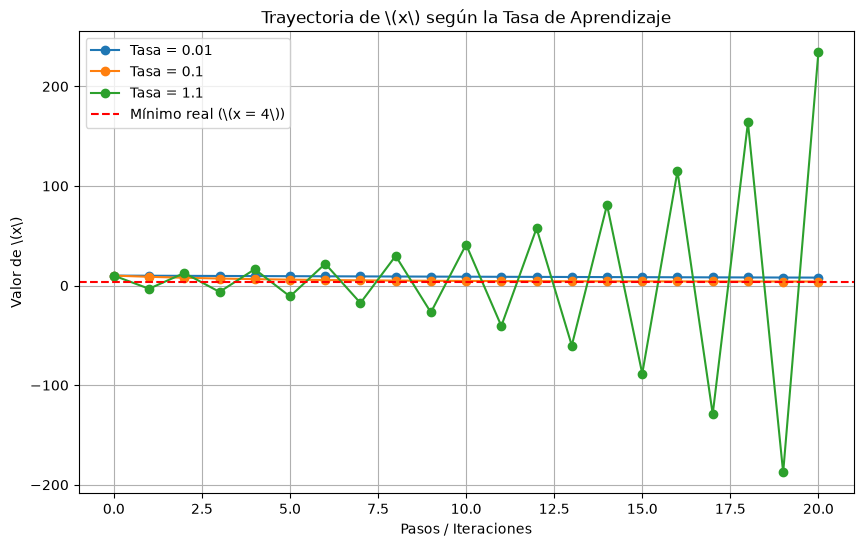

=== RESULTADOS FINALES DESPUÉS DE 20 PASOS ===
Tasa 0.01 | x final:   8.005648 | Error respecto a x=4:   4.005648
Tasa 0.10 | x final:   4.069175 | Error respecto a x=4:   0.069175
Tasa 1.10 | x final: 234.025600 | Error respecto a x=4: 230.025600


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Definición de la función y su derivada
def f(x):
    return (x - 4)**2 + 1

def df(x):
    return 2 * (x - 4)

# Configuración inicial
x_inicial = 10.0
pasos = 20
tasas = [0.01, 0.1, 1.1]

trayectorias = {}

# --- 1 y 2. Algoritmo de Descenso de Gradiente y simulación ---
plt.figure(figsize=(10, 6))

for lr in tasas:
    x = x_inicial
    historial_x = [x]
    
    for _ in range(pasos):
        x = x - lr * df(x)
        historial_x.append(x)
        
    trayectorias[lr] = historial_x
    plt.plot(range(pasos + 1), historial_x, marker='o', label=f'Tasa = {lr}')

# Corrección aquí: Usamos 'r' al inicio y '$' para la notación matemática
plt.axhline(y=4, color='r', linestyle='--', label=r'Mínimo real (\(x = 4\))')
plt.title(r'Trayectoria de \(x\) según la Tasa de Aprendizaje')
plt.xlabel('Pasos / Iteraciones')
plt.ylabel(r'Valor de \(x\)')
plt.legend()
plt.grid(True)
plt.show()

# --- 3. Comparación de x final ---
print("=== RESULTADOS FINALES DESPUÉS DE 20 PASOS ===")
for lr, hist in trayectorias.items():
    x_final = hist[-1]
    print(f"Tasa {lr:4.2f} | x final: {x_final:10.6f} | Error respecto a x=4: {abs(x_final - 4):10.6f}")

**Respuesta**
- **¿Todas llegan cerca del mínimo?**
  No. Solo la tasa intermedia llega eficazmente al mínimo.
- **Comportamiento según la Tasa de Aprendizaje:**
  - **Tasa muy pequeña ($\alpha = 0.01$):** Avanza extremadamente lento. En 20 pasos no le da tiempo suficiente para alcanzar el mínimo ($x=4$) debido
    a que los pasos que da son minúsculos.
  - **Tasa intermedia ($\alpha = 0.1$):** Converge de forma suave, rápida y estable hacia $x = 4$ en pocos pasos.
  - **Tasa muy grande ($\alpha = 1.1$): Inestable / Divergente.** Como la tasa es demasiado grande, el paso sobrepasa el mínimo y se "dispara" o
    explota oscilando cada vez más lejos de $x = 4$ (los valores de $x$ oscilan alternando signos y creciendo descontroladamente).